# 01 – Exploration des données

Objectif : vérifier les données téléchargées et se faire une première idée des actions : rendements, volatilité, drawdowns et corrélations.

Avant de lancer ce notebook : `python src/ingest.py` (ou `--demo` sans internet).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from analytics import (daily_returns, drawdown, load_prices, summary_table)

plt.rcParams['figure.figsize'] = (11, 5)
pd.options.display.float_format = '{:.3f}'.format

## 1. Charger les prix

In [2]:
prices = load_prices(ROOT / 'data' / 'market.duckdb')
print(f'{prices.shape[1]} tickers, du {prices.index.min():%d/%m/%Y} au {prices.index.max():%d/%m/%Y}')
prices.tail()

50 tickers, du 02/01/2015 au 06/11/2026


ticker,AAPL,ABBV,ABT,ADBE,AMGN,AMZN,AVGO,BAC,BRK-B,CAT,...,T,TMO,TXN,UNH,UNP,UPS,V,VZ,WMT,XOM
date,,,,,,,,,,,,,,,,,,,,,
2026-11-02,338.320,288.840,110.160,251.470,465.450,245.630,322.230,49.570,556.110,613.620,...,21.440,682.650,302.020,400.440,307.000,109.710,425.510,45.050,127.690,179.670
2026-11-03,331.900,286.000,109.400,246.140,461.260,250.690,332.130,49.660,557.070,623.940,...,21.390,698.340,312.490,404.440,303.430,109.170,420.420,45.240,124.860,177.460
2026-11-04,349.510,294.830,115.510,248.480,478.480,266.030,325.480,51.630,579.090,591.300,...,21.830,706.160,311.490,409.380,308.530,114.310,436.570,46.170,129.170,169.270
2026-11-05,344.170,288.240,113.600,246.440,460.280,260.210,291.530,49.760,572.330,553.640,...,21.820,676.940,278.150,395.720,297.950,111.040,422.590,46.120,127.720,165.300
2026-11-06,342.370,291.310,109.930,239.300,460.420,259.300,293.690,49.420,570.890,558.630,...,21.630,694.760,277.360,394.150,290.160,108.300,422.650,45.690,125.520,165.870


## 2. Contrôle qualité

Valeurs manquantes par ticker (les entreprises entrées en bourse après 2015 en ont au début).

In [3]:
prices.isna().sum().sort_values(ascending=False).head(10)

ticker
AAPL    0
PFE     0
MCD     0
META    0
MRK     0
MS      0
MSFT    0
NFLX    0
NKE     0
NVDA    0
dtype: int64

## 3. Performance cumulée

Toutes les actions ramenées à 1 au départ pour les comparer.

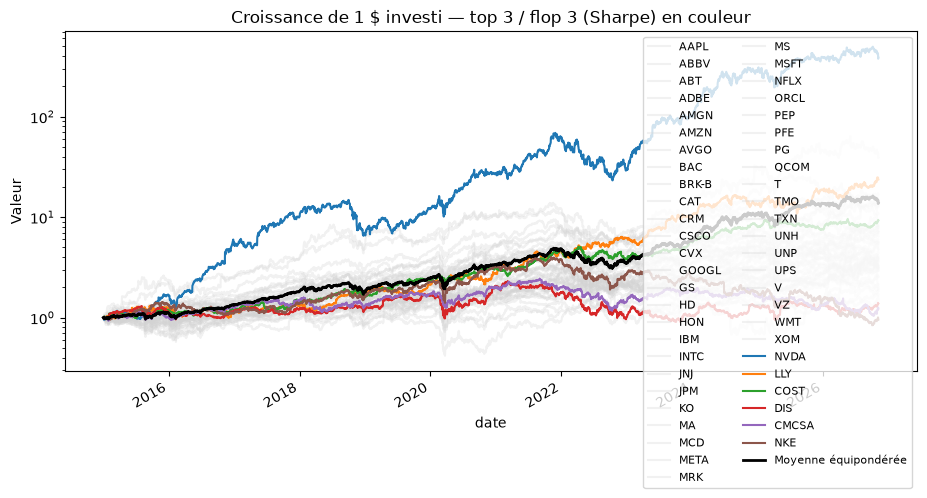

In [4]:
normalized = prices / prices.bfill().iloc[0]

# On met en couleur les 3 meilleures et 3 pires actions (par Sharpe), le reste reste gris.
ranked = summary_table(daily_returns(prices)).index
highlight = list(ranked[:3]) + list(ranked[-3:])

ax = normalized.drop(columns=highlight).plot(legend=False, alpha=0.3, color='lightgrey')
normalized[highlight].plot(ax=ax, linewidth=1.5)
normalized.mean(axis=1).plot(ax=ax, color='black', linewidth=2, label='Moyenne équipondérée')
ax.set(title='Croissance de 1 $ investi — top 3 / flop 3 (Sharpe) en couleur', ylabel='Valeur', yscale='log')
ax.legend(fontsize=8, ncol=2);

## 4. Tableau récapitulatif

Rendement annualisé, volatilité, Sharpe et pire perte de chaque action.

In [5]:
returns = daily_returns(prices)
stats = summary_table(returns)
stats

,rendement_annuel,volatilite_annuelle,sharpe,max_drawdown
ticker,,,,
NVDA,0.656,0.481,1.288,-0.663
LLY,0.307,0.298,1.046,-0.345
COST,0.207,0.215,0.984,-0.314
AVGO,0.363,0.396,0.981,-0.483
MSFT,0.245,0.276,0.933,-0.371
AAPL,0.251,0.287,0.926,-0.385
AMZN,0.270,0.331,0.886,-0.561
GOOGL,0.224,0.293,0.836,-0.443
MA,0.195,0.262,0.810,-0.410


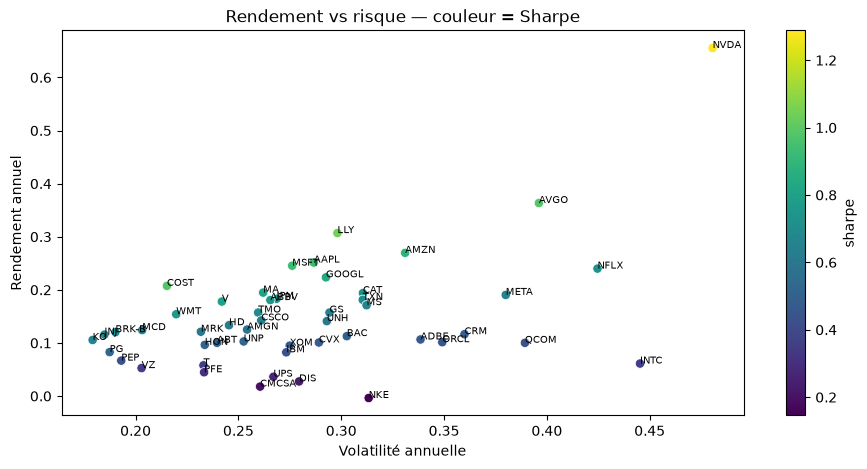

In [6]:
ax = stats.plot.scatter(
    x='volatilite_annuelle', y='rendement_annuel',
    c='sharpe', cmap='viridis', s=45, edgecolor='white', linewidth=0.5,
)
for t, row in stats.iterrows():
    ax.annotate(t, (row['volatilite_annuelle'], row['rendement_annuel']), fontsize=7)
ax.set(title='Rendement vs risque — couleur = Sharpe', xlabel='Volatilité annuelle', ylabel='Rendement annuel');

## 5. Drawdown du portefeuille équipondéré

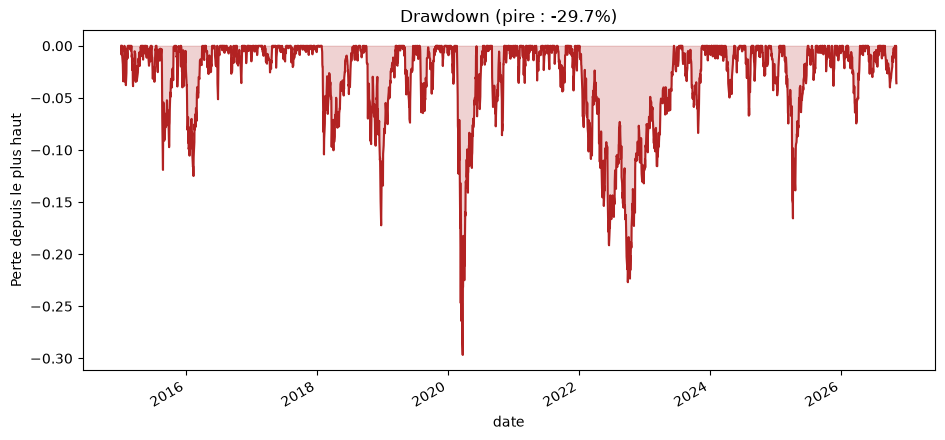

In [7]:
portfolio = returns.mean(axis=1)
dd = drawdown(portfolio)
ax = dd.plot(color='firebrick')
ax.fill_between(dd.index, dd, 0, color='firebrick', alpha=0.2)
ax.set(title=f'Drawdown (pire : {dd.min():.1%})', ylabel='Perte depuis le plus haut');

## 6. Corrélations

Des actions très corrélées apportent peu de diversification.

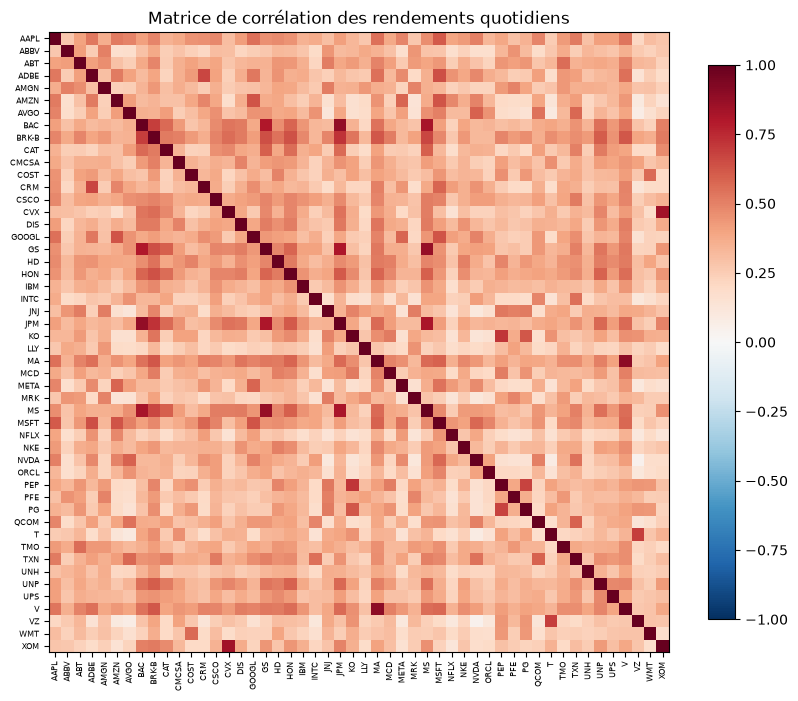

In [8]:
corr = returns.corr()
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Matrice de corrélation des rendements quotidiens');

In [9]:
print(f"Corrélation moyenne entre actions : {corr.where(~(corr == 1)).stack().mean():.2f}")

Corrélation moyenne entre actions : 0.35


## À noter pour la suite

- Ce que tu observes : quelles actions dominent ? Les corrélations augmentent-elles en crise ?
- Prochaine étape : modèles dbt (rendements, volatilité glissante, momentum 12-1) et tests de qualité.
- Garde en tête le biais du survivant : ces 50 actions sont les gagnantes d'aujourd'hui.